# Kia and Hyundai Vehicle Theft Analysis and Visualization

Explore vehicle-theft patterns using four datasets and explanatory visualizations.

**Tools:** Python, pandas, Matplotlib, Plotly

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import plotly.express as px

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

# Consistent design colors
KIA_COLOR = "#D62728"
OTHER_COLOR = "#BDBDBD"
ACCENT_COLOR = "#1F4E79"

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Python setup complete.")

Python setup complete.


In [2]:
# Locate the four datasets automatically.
search_folders = [Path("data")]
required_files = {
    "map": "Car_Thefts_Map.xlsx",
    "milwaukee": "Milwaukee_Vehicle_Thefts.xlsx",
    "cities": "Kia_Hyundai_City_Thefts.xlsx",
    "vice": "VICE_Vehicle_Theft_Data.xlsx",
}

paths = {}
for key, filename in required_files.items():
    match = next((folder / filename for folder in search_folders if (folder / filename).exists()), None)
    if match is None:
        raise FileNotFoundError(
            f"Could not find {filename}. Put it in the same folder as this notebook."
        )
    paths[key] = match

for key, path in paths.items():
    print(f"{key:10s}: {path}")

map       : /Users/ryanmaxam/Desktop/Week 5 & 6 Assignment - DSC 640/carTheftsMap.xlsx
milwaukee : /Users/ryanmaxam/Desktop/Week 5 & 6 Assignment - DSC 640/KiaHyundaiMilwaukeeData.xlsx
cities    : /Users/ryanmaxam/Desktop/Week 5 & 6 Assignment - DSC 640/kiaHyundaiThefts.xlsx
vice      : /Users/ryanmaxam/Desktop/Week 5 & 6 Assignment - DSC 640/Motherboard VICE News Kia Hyundai Theft Data.xlsx


## 2. Import and clean all four datasets

For this project, I first analyzed all four datasets and cleaned them to easily import them into Jupyter Notebook.

In [3]:
# Dataset 1: agency-level annual car thefts and coordinates
map_data = pd.read_excel(paths["map"], skiprows=1)
map_numeric = [
    "countCarThefts2019", "countCarThefts2020", "countCarThefts2021",
    "countCarThefts2022", "latitude", "longitude", "percentChange2019to2022"
]
for col in map_numeric:
    map_data[col] = pd.to_numeric(map_data[col], errors="coerce")

# Dataset 2: Milwaukee monthly Kia/Hyundai and other thefts
milwaukee = pd.read_excel(paths["milwaukee"], skiprows=1)
for col in ["year", "countKiaHyundaiThefts", "countOtherThefts", "percentKiaHyundai"]:
    milwaukee[col] = pd.to_numeric(milwaukee[col], errors="coerce")
milwaukee["date"] = pd.to_datetime(
    milwaukee["month"].astype(str) + " " + milwaukee["year"].astype("Int64").astype(str),
    format="%b %Y", errors="coerce"
)
milwaukee = milwaukee.dropna(subset=["date"]).sort_values("date")

# Dataset 3: monthly data for multiple cities
city_thefts = pd.read_excel(paths["cities"], skiprows=1)
for col in ["year", "countKiaHyundaiThefts", "countOtherThefts", "percentKiaHyundai"]:
    city_thefts[col] = pd.to_numeric(city_thefts[col], errors="coerce")
city_thefts["date"] = pd.to_datetime(
    city_thefts["month"].astype(str) + " " + city_thefts["year"].astype("Int64").astype(str),
    format="%b %Y", errors="coerce"
)
city_thefts["city_state"] = city_thefts["city"].astype(str) + ", " + city_thefts["state"].astype(str)
city_thefts = city_thefts.dropna(subset=["date"]).sort_values("date")

# Dataset 4: reshape the wide VICE workbook into a tidy city-month table
vice_raw = pd.read_excel(paths["vice"], sheet_name="Data", header=None)
city_row = vice_raw.iloc[0]
metric_row = vice_raw.iloc[1]
dates = pd.to_datetime(vice_raw.iloc[2:, 0], errors="coerce")

frames = []
for start in range(1, vice_raw.shape[1], 3):
    if start + 2 >= vice_raw.shape[1]:
        break
    city = city_row.iloc[start]
    if pd.isna(city) or str(city).strip() == "":
        continue
    frame = pd.DataFrame({
        "date": dates.values,
        "city": str(city).strip(),
        "countKiaHyundaiThefts": pd.to_numeric(vice_raw.iloc[2:, start], errors="coerce").values,
        "countAllThefts": pd.to_numeric(vice_raw.iloc[2:, start + 1], errors="coerce").values,
        "percentKiaHyundai": pd.to_numeric(vice_raw.iloc[2:, start + 2], errors="coerce").values,
    })
    frames.append(frame)

vice_tidy = pd.concat(frames, ignore_index=True).dropna(subset=["date"])

print("Rows loaded:")
print(f"  Car theft map:       {len(map_data):,}")
print(f"  Milwaukee monthly:   {len(milwaukee):,}")
print(f"  Multi-city monthly:  {len(city_thefts):,}")
print(f"  VICE city-month:     {len(vice_tidy):,}")

Rows loaded:
  Car theft map:       556
  Milwaukee monthly:   48
  Multi-city monthly:  552
  VICE city-month:     3,150


In [4]:
# Quick data-quality summary
quality = pd.DataFrame({
    "Dataset": ["Car Thefts Map", "Milwaukee", "Multi-city", "VICE"],
    "Rows": [len(map_data), len(milwaukee), len(city_thefts), len(vice_tidy)],
    "Earliest Date/Year": [
        2019,
        milwaukee["date"].min().date(),
        city_thefts["date"].min().date(),
        vice_tidy["date"].min().date(),
    ],
    "Latest Date/Year": [
        2022,
        milwaukee["date"].max().date(),
        city_thefts["date"].max().date(),
        vice_tidy["date"].max().date(),
    ],
})
quality

,Dataset,Rows,Earliest Date/Year,Latest Date/Year
0,Car Thefts Map,556,2019,2022
1,Milwaukee,48,2019-01-01,2022-12-01
2,Multi-city,552,2019-01-01,2022-12-01
3,VICE,3150,2019-12-01,2023-08-01


## 3. Visual 1 — Stacked area chart

In this first visualization, I used a stacked chart in order to show whether the rise in thefts was driven by Kia/Hyundai vehicles, other vehicles, or both.

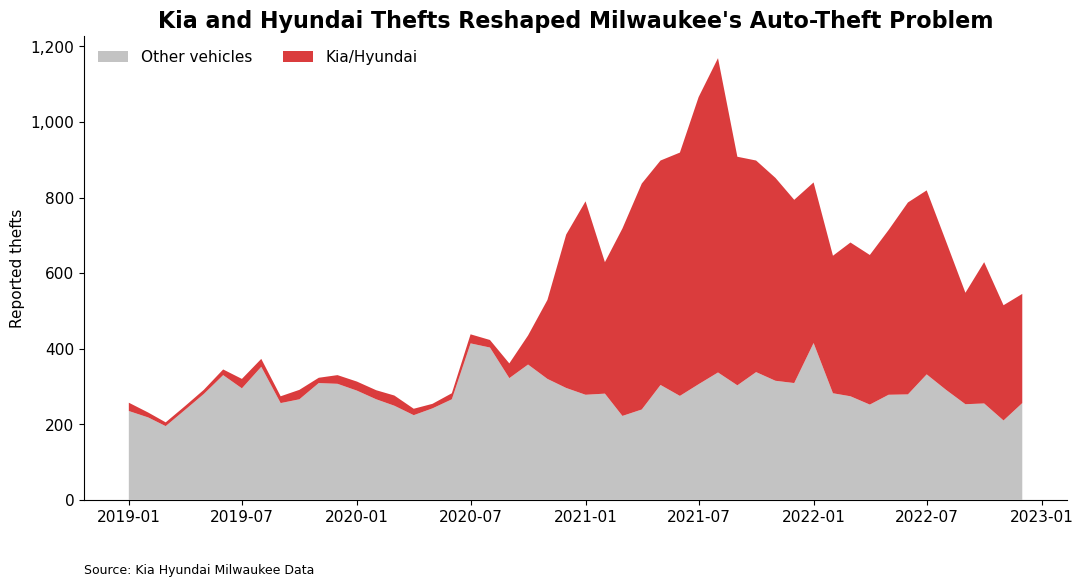

In [5]:
fig, ax = plt.subplots()
ax.stackplot(
    milwaukee["date"],
    milwaukee["countOtherThefts"].fillna(0),
    milwaukee["countKiaHyundaiThefts"].fillna(0),
    labels=["Other vehicles", "Kia/Hyundai"],
    colors=[OTHER_COLOR, KIA_COLOR],
    alpha=0.9,
)
ax.set_title("Kia and Hyundai Thefts Reshaped Milwaukee's Auto-Theft Problem")
ax.set_xlabel("")
ax.set_ylabel("Reported thefts")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="upper left", frameon=False, ncol=2)
ax.text(0, -0.16, "Source: Kia Hyundai Milwaukee Data", transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

## 4. Visual 2 — Donut charts

For my second visualization, I created a donut chart for Milwaukee that compares before and after the surge of thefts that involved Kia/Hyundai vehicles in 2019-2020 compared to 2021-2022.

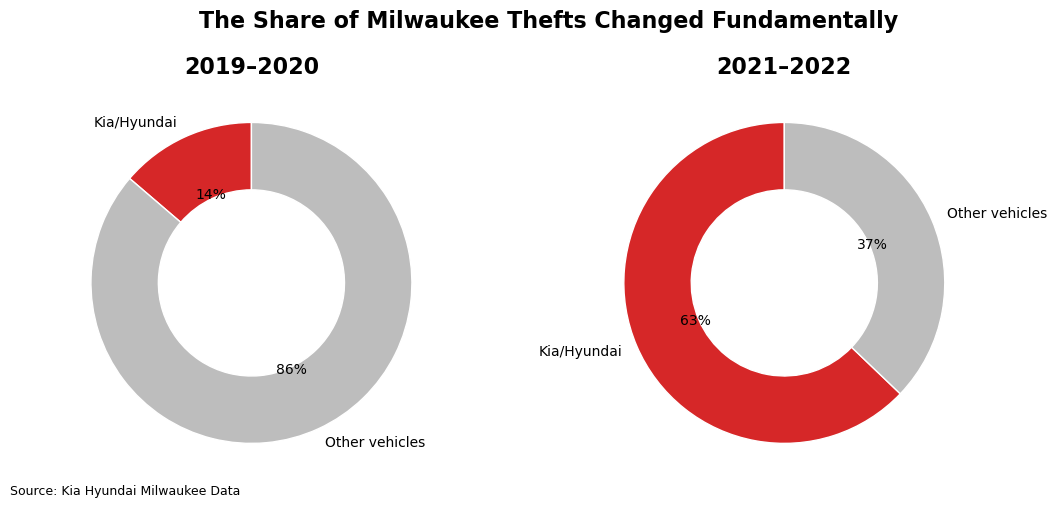

In [6]:
period_data = (
    milwaukee.assign(period=np.where(milwaukee["year"] <= 2020, "2019–2020", "2021–2022"))
    .groupby("period", as_index=False)[["countKiaHyundaiThefts", "countOtherThefts"]]
    .sum()
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (_, row) in zip(axes, period_data.iterrows()):
    values = [row["countKiaHyundaiThefts"], row["countOtherThefts"]]
    ax.pie(
        values,
        labels=["Kia/Hyundai", "Other vehicles"],
        autopct="%1.0f%%",
        startangle=90,
        colors=[KIA_COLOR, OTHER_COLOR],
        wedgeprops={"width": 0.42, "edgecolor": "white"},
        textprops={"fontsize": 10},
    )
    ax.set_title(row["period"])

fig.suptitle("The Share of Milwaukee Thefts Changed Fundamentally", fontsize=16, fontweight="bold")
fig.text(0.01, 0.01, "Source: Kia Hyundai Milwaukee Data", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Visual 3 — Treemap

For my third visualization, I choose a tree map to show the 2022 burden was concentrated in a small number of cities.

In [7]:
city_2022 = (
    city_thefts.loc[city_thefts["year"] == 2022]
    .groupby("city_state", as_index=False)["countKiaHyundaiThefts"]
    .sum()
    .rename(columns={"countKiaHyundaiThefts": "thefts"})
)
city_2022 = city_2022.loc[city_2022["thefts"] > 0].sort_values("thefts", ascending=False)

fig = px.treemap(
    city_2022,
    path=["city_state"],
    values="thefts",
    color="thefts",
    color_continuous_scale="Reds",
    title="The 2022 Kia/Hyundai Theft Burden Was Highly Concentrated",
)
fig.update_traces(texttemplate="%{label}<br>%{value:,.0f}")
fig.update_layout(
    height=650,
    margin=dict(t=70, l=15, r=15, b=45),
    annotations=[dict(
        text="Source: Kia Hyundai Thefts",
        x=0, y=-0.06, xref="paper", yref="paper", showarrow=False, font=dict(size=11)
    )],
)
fig.show()

## 6. Visual 4 — Stacked categorical bars

For my 4th visualization, I choose a stacked categorical bars to show the largest increase in the highest volume cities in 2022. 

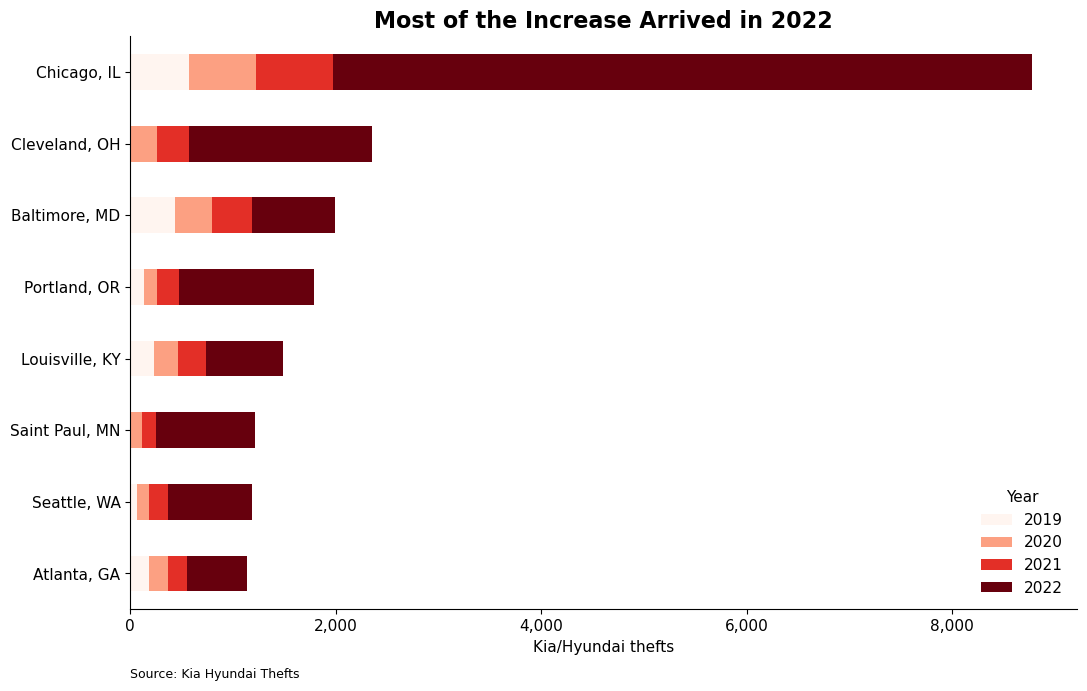

In [8]:
top_cities = (
    city_thefts.groupby("city_state")["countKiaHyundaiThefts"]
    .sum().nlargest(8).index
)
selected = (
    city_thefts.loc[city_thefts["city_state"].isin(top_cities)]
    .groupby(["city_state", "year"], as_index=False)["countKiaHyundaiThefts"]
    .sum()
)
pivot = selected.pivot(index="city_state", columns="year", values="countKiaHyundaiThefts").fillna(0)
pivot = pivot.loc[pivot.sum(axis=1).sort_values().index]

ax = pivot.plot(kind="barh", stacked=True, figsize=(11, 7), colormap="Reds")
ax.set_title("Most of the Increase Arrived in 2022")
ax.set_xlabel("Kia/Hyundai thefts")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Year", frameon=False, loc="lower right")
ax.text(0, -0.12, "Source: Kia Hyundai Thefts", transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

## 7. Visual 5 — Area chart

For my 5th visualization, I choose to use an area chart to show a broader theft increase of Kia/Hyundai vehicles. This visual aggregates annual reported thefts across different agencies in the map dataset.

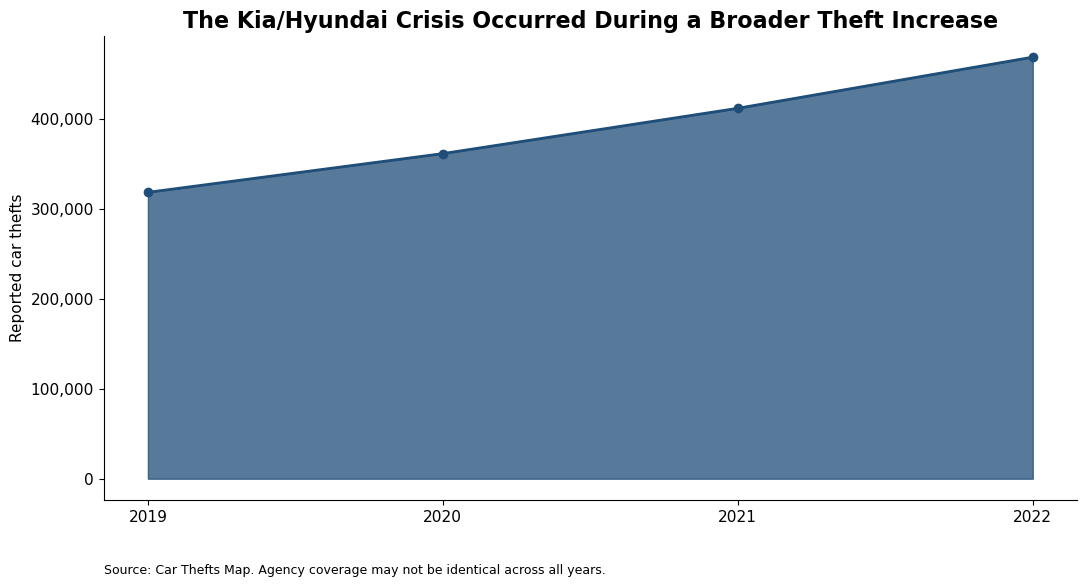

In [9]:
map_annual = pd.DataFrame({
    "year": [2019, 2020, 2021, 2022],
    "thefts": [
        map_data["countCarThefts2019"].sum(skipna=True),
        map_data["countCarThefts2020"].sum(skipna=True),
        map_data["countCarThefts2021"].sum(skipna=True),
        map_data["countCarThefts2022"].sum(skipna=True),
    ],
})

fig, ax = plt.subplots()
ax.fill_between(map_annual["year"], map_annual["thefts"], alpha=0.75, color=ACCENT_COLOR)
ax.plot(map_annual["year"], map_annual["thefts"], marker="o", linewidth=2, color=ACCENT_COLOR)
ax.set_title("The Kia/Hyundai Crisis Occurred During a Broader Theft Increase")
ax.set_xlabel("")
ax.set_ylabel("Reported car thefts")
ax.set_xticks(map_annual["year"])
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.text(
    0, -0.16,
    "Source: Car Thefts Map. Agency coverage may not be identical across all years.",
    transform=ax.transAxes, fontsize=9
)
plt.tight_layout()
plt.show()

## 8. Visual 6 — Pie chart

For my 6th visualization, I choose a pie chart for a small set of cities for a large amount the latest reported volume. This chart uses the last 12 months available from the VICE dataset provided.

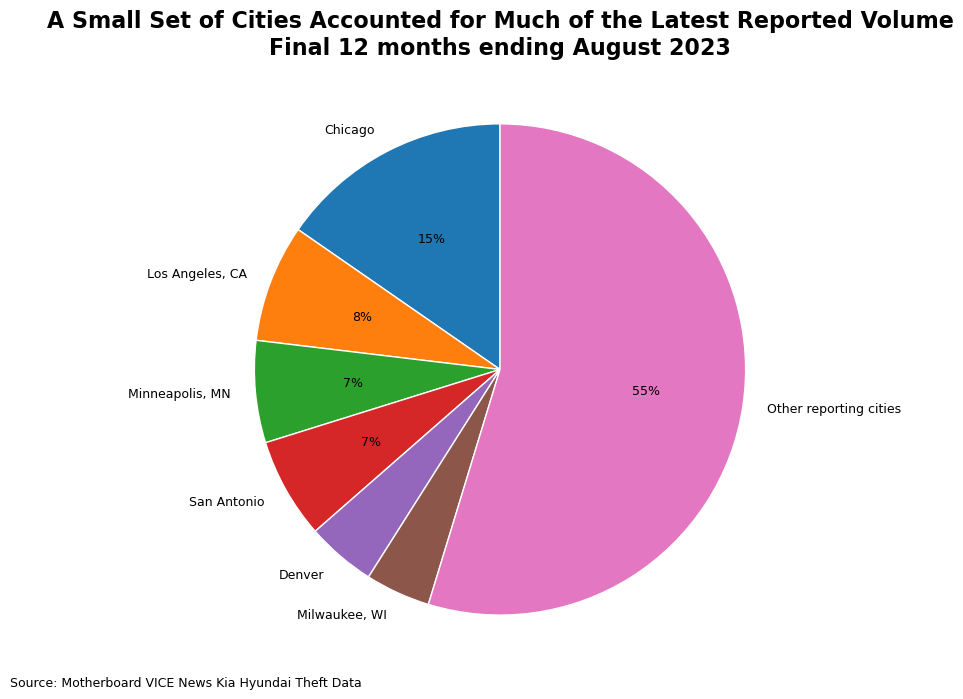

In [10]:
latest_date = vice_tidy["date"].max()
latest_start = latest_date - pd.DateOffset(months=11)

vice_latest_city = (
    vice_tidy.loc[vice_tidy["date"].between(latest_start, latest_date)]
    .groupby("city", as_index=False)["countKiaHyundaiThefts"]
    .sum()
    .sort_values("countKiaHyundaiThefts", ascending=False)
)

top6 = vice_latest_city.head(6).copy()
other_total = vice_latest_city.iloc[6:]["countKiaHyundaiThefts"].sum()
pie_data = pd.concat([
    top6[["city", "countKiaHyundaiThefts"]],
    pd.DataFrame({"city": ["Other reporting cities"], "countKiaHyundaiThefts": [other_total]})
], ignore_index=True)
pie_data = pie_data.loc[pie_data["countKiaHyundaiThefts"] > 0]

fig, ax = plt.subplots(figsize=(10, 7))
ax.pie(
    pie_data["countKiaHyundaiThefts"],
    labels=pie_data["city"],
    autopct=lambda p: f"{p:.0f}%" if p >= 5 else "",
    startangle=90,
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": 9},
)
ax.set_title(
    "A Small Set of Cities Accounted for Much of the Latest Reported Volume\n"
    f"Final 12 months ending {latest_date:%B %Y}"
)
fig.text(0.01, 0.01, "Source: Motherboard VICE News Kia Hyundai Theft Data", fontsize=9)
plt.tight_layout()
plt.show()

## 9. Key findings and call to action

For this project, I included 6 different visualization to support a way to prevent the issue at hand rather than just creating a general awareness of this issue. Some key findings include:

- The greatest burden that neighborhoods and owners face is the distribute steering wheel locks.
- Create a recurring software update and owner education events for Kia/Hyundai vehicles.
- Use theft locations and time patterns to lead law enforcement to these areas to prevent these issues rather than using only citywide averages
- Finally, create a monthly tracker to understand the total thefts, Kia/Hyundai thefts, recovery rates, software updates, and lock distribution.

## 10. Audience, purpose, medium, design, and ethical considerations

This story was created for the state officials, law enforcement, and community leadership. The audience for this project is familiar with the public safety decisions but could potentially not understand the datasets or statistical terminology. For this specific reason, we want to gear this presentation towards using simple terms, direct explanations, and simple comparisons rather than using model based analysis. The purpose of this project is to show present these findings to the decision makers and to approve a coordinated prevention program which combines the suggestions provided such as steering wheel lock distribution, software updates, owner education, and hotspot based patrol deployment. I choose to use a Jupyter Notebook as the medium for this project because it allows me to combine the coding, visuals, and descriptions into one file.

For the design of my project, I including Gestalt principles by combining related info, maintaining consistent visuals, and using proximity and alignment to connect each of the charts to the goal of the interpretation. For example, I used red consistently to show the thefts for Kia/Hyundai because this shows urgency, while the grey represents other vehicle thefts and the dark blue gives more broad context. The titles for each visual are large and bolded, chart elements are aligned, and spacing is used to separate each stage of the story. I used a sequence of visuals to move from the Milwaukee trend to composition, city comparisions, broader environments, and the lastest reporting. 

I had to use many different data changes for this project. First, I had to remove title rows, convert numeric fields, update dates, and missing observations were excluded when needed. Ethical risks were taken into consideration for this project even though we didn't have any personal identifiable information. City comparisons can potential be misleading due to agencies having different ways of reporting the data. The visuals I used for this project identify the sources used, avoid claiming causation, and label filters being used. In order to confirm the credibility of the data we should check it against the original agency and VICE documentation. Ways to minimize ethical issues is publish the methods being used, report any missing data, and using population based rates, and auditing the data.